In [1]:
import glob
import yaml
import ml_collections
from tqdm import tqdm
from arch import arch_model
from utils.utils import *
from utils.metric import *
from utils.eval_portfolio.summary import *
from utils.eval_portfolio.strategies import log_return_to_price
from utils.file_manager import LOCAL_BASE_DIRECTORY, quantDiffusionPath
from models.modernTCN_cross_attention import ModernTCN
from torch.utils.data import DataLoader, TensorDataset
from modules.diffusion import TimeSeriesGaussianDiffusion, generate_cosine_schedule


file_manager = quantDiffusionPath()
gc.collect()

0

# Preprocessing

In [2]:
from scipy.ndimage import gaussian_filter1d


def calculate_garch_sde_params(returns_2d, window_size=256):
    T, F = returns_2d.shape
    # 0: sigma_t, 1: high-pass filtered vol
    results_3d = np.zeros((T, F, 2), dtype=np.float64)

    warnings.filterwarnings("ignore", category=RuntimeWarning, module="arch")

    left_offset = 0  # 앞서 논의한 Burn-in (5일) 적용
    eps = 1e-10
    lam = 0.94

    for j in range(F):
        asset_returns = returns_2d[:, j].astype(np.float64)

        # 1) Global GARCH Fitting (Robust하게 수정)
        try:
            # Rescale=True 사용 시 내부 스케일링 값을 정확히 반영하기 위해 자동 스케일링 허용
            am = arch_model(
                asset_returns,
                vol="Garch",
                p=1,
                q=1,
                mean="Zero",
                dist="ged",
                rescale=True,
            )
            res = am.fit(disp="off", show_warning=False)

            # 파라미터 추출 (Scale 보정: sigma_orig = sigma_rescaled / scale)
            s = res.scale
            omega = res.params["omega"] / (s**2)
            alpha = res.params["alpha[1]"]
            beta = res.params["beta[1]"]
        except:
            # Fallback: 일반적인 시장 파라미터 (안정적 수렴값)
            omega = np.var(asset_returns) * 0.05
            alpha, beta = 0.05, 0.90

        # 2) Rolling Loop 최적화
        # 각 t 시점에 대해 start_idx부터 t까지의 recursion을 벡터화 준비
        for t in range(T):
            start_idx = max(0, t - left_offset)
            end_idx = min(start_idx + window_size, T)

            # Local window 추출 및 Clipping (벡터화)
            local_data = asset_returns[start_idx:end_idx]
            m, s_dev = np.mean(local_data), np.std(local_data)
            if s_dev > 0:
                local_data = np.clip(local_data, m - 5 * s_dev, m + 5 * s_dev)

            # Backcast 초기값 계산 (함수 호출 대신 인라인 최적화)
            n_local = len(local_data)
            weights = lam ** np.arange(n_local - 1, -1, -1)
            h = np.sum(weights * (local_data**2)) / (weights.sum() + eps)
            h = max(h, eps)

            # 핵심: local_t_idx (현재 t가 윈도우 내 어디인지)
            curr_in_window = t - start_idx

            # Recursion (k=0 to curr_in_window-1)
            # t시점의 h_t를 구하기 위해 t-1까지의 r_k 사용
            if curr_in_window > 0:
                # 이 루프는 매우 짧으므로(max 5회) 유지하되 연산 최소화
                for k in range(curr_in_window):
                    h = omega + alpha * (local_data[k] ** 2) + beta * h

            results_3d[t, j, 0] = np.sqrt(max(h, eps))

        # 3) Post-processing (Vectorized)

        # logvol = np.log(results_3d[:, j, 0] + eps)
        logvol = np.log(gaussian_filter1d(results_3d[:, j, 0], sigma=1.5))
        results_3d[:, j, 1] = logvol

    return results_3d

In [3]:
def fit_transform_garch_12d(train_data):
    """
    Train 데이터를 미래참조 SDE 파라미터를 이용해 12차원(Z C + V C)으로 분해합니다.
    Z: 기존 Gaussianize 스케일링, V(로그 변동성): QuantileTransformer.
    """
    T, C = train_data.shape

    # 1. 미래참조 TV-SDE 파라미터 산출 (한 번에 모든 자산 처리)
    sde_results_3d = calculate_garch_sde_params(train_data)

    # 2. 조건부 변동성 (스무딩 채널 1 권장)
    sigma_t_raw = sde_results_3d[:, :, 0]  # (T, C)
    sigma_t_log = sde_results_3d[:, :, 1]  # (T, C)

    # 3. 잔차(Z) 및 로그 변동성(V) 산출 (Vectorized)
    Z_t = train_data / (sigma_t_raw + 1e-8)
    # 1. 기본 로그 변동성 산출 (GARCH [0]번 인덱스 베이스)
    V_t = sigma_t_log

    scaled_12d = np.concatenate([Z_t, V_t], axis=1)
    print(f"✅ GARCH 분해 완료: 잔차(Z) {C}ch, 로그변동성(V) {C}ch (V=분위수 변환)")

    scaled_12d, scalers = scaling(scaled_12d)

    return scaled_12d, scalers


def inverse_garch_12d_to_6d(generated_12d, scalers):
    """
    Diffusion이 생성한 12차원 데이터를 원본 6차원 수익률로 완벽하게 복원합니다.

    Args:
        generated_12d: (B, 12, T) 또는 (B, T, 12) 형태의 텐서/배열
        scalers_Z: Train에서 학습한 잔차(Z) 스케일러 리스트
        scalers_V: Train에서 학습한 로그변동성(V) 스케일러 리스트
    Returns:
        X_reconstructed: 복원된 (B, 6, T) 또는 (B, T, 6) 형태의 원본 6차원 텐서
    """
    # 3. 12차원 반갈죽 (앞 6: 잔차 Z, 뒤 6: 로그변동성 V)
    inv_12d = inverse_scaling(generated_12d.transpose(1, 2), scalers)

    Z_inv = inv_12d[:, :6, :]
    V_inv = inv_12d[:, 6:, :]

    # 5. 변동성 복구 (로그 해제)
    # 💡 방어 로직: 학습 초반 모델이 미친 값을 뱉을 때 exp가 우주로 가는 것 방지 (max 값을 약 10 내외로 제한)
    V_inv = np.clip(V_inv, a_min=-20.0, a_max=10.0)
    sigma_t = np.exp(V_inv)

    # 6. 최종 6차원 SDE 합성 (Z * sigma)
    # 평온했던 Z 노이즈에 변동성 스파이크를 때려 박아 현실 세계의 폭락/폭등을 구현
    X_reconstructed = Z_inv * sigma_t

    return X_reconstructed
    # return np.transpose(X_reconstructed, (0, 2, 1))

In [4]:
# --- [0. 준비 단계] ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seq_len = 256

# 데이터 로드
df = pd.read_csv(f"./data/indices2.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
df.set_index("Date", inplace=True)
df = df.apply(pd.to_numeric).astype(float)

log_returns = np.log1p(df.pct_change()).dropna().values
init_price_raw = np.array(df)[:-1, :]

# --- [1. Early Split (시간 순 분할)] ---
total_len = len(log_returns)
train_size = int(0.7 * total_len)

train_raw = log_returns[:train_size]
test_raw = log_returns[train_size:]  # Test는 원본 6차원 그대로 대기

train_init_raw = init_price_raw[:train_size]
test_init_raw = init_price_raw[train_size:]

# --- [2. GARCH 12차원 전처리 (Train ONLY)] ---
# Train만 GARCH로 12차원 분해 및 스케일링 수행
train_12d, scalers = fit_transform_garch_12d(log_returns)
# scaled 행 0 = 원본 시계열 인덱스 ffd_burn (FFD burn-in 제거됨)

train_12d = train_12d[: train_size]

# --- [3. Windowing (시퀀스 쪼개기)] ---
# Train은 12차원 윈도우 생성
train_windowed = torch.from_numpy(rolling_window(train_12d, seq_len)).float()
train_init_windowed = (
    torch.from_numpy(train_init_raw[: -(seq_len - 1)]).float().unsqueeze(1)
)

test_windowed = torch.from_numpy(rolling_window(test_raw, seq_len)).float()
test_init_windowed = (
    torch.from_numpy(test_init_raw[: -(seq_len - 1)]).float().unsqueeze(1)
)

# (B, T, C) -> (B, C, T) 축 변환
training_data = train_windowed.clone().detach()  # (B, 256, 12)
test_data = test_windowed.clone().detach()  # (B, 256, 6)

training_set = TensorDataset(training_data)
test_set = TensorDataset(test_data)

train_dl = DataLoader(training_set, batch_size=256, shuffle=False)
test_dl = DataLoader(test_set, batch_size=256, shuffle=False)

print("\n🚀 데이터 준비 완료!")
print(f"Train DataLoader 배치 크기: {next(iter(train_dl))[0].shape}")
print(f"Test DataLoader 배치 크기: {next(iter(test_dl))[0].shape}")

c:\Users\asas4\AppData\Local\miniconda3\envs\research\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)


✅ GARCH 분해 완료: 잔차(Z) 6ch, 로그변동성(V) 6ch (V=분위수 변환)


c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\utils\gaussianize.py:190: UserWarning: Warning: No convergence after 150 iterations. Increase max_iter.
  warnings.warn(
c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\utils\gaussianize.py:190: UserWarning: Warning: No convergence after 150 iterations. Increase max_iter.
  warnings.warn(



🚀 데이터 준비 완료!
Train DataLoader 배치 크기: torch.Size([256, 256, 12])
Test DataLoader 배치 크기: torch.Size([256, 256, 6])


Asset 0 - KS Statistic ($D$): 0.035424
p < 0.001


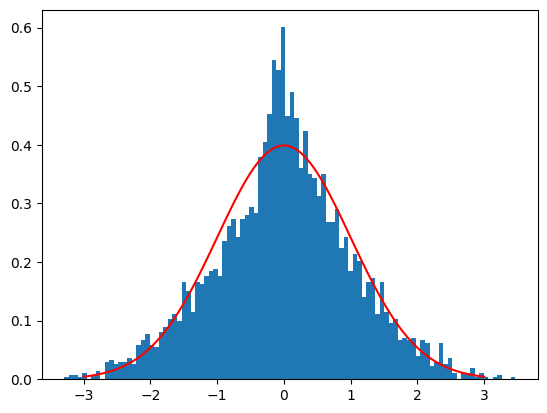

Asset 1 - KS Statistic ($D$): 0.031104
p < 0.001


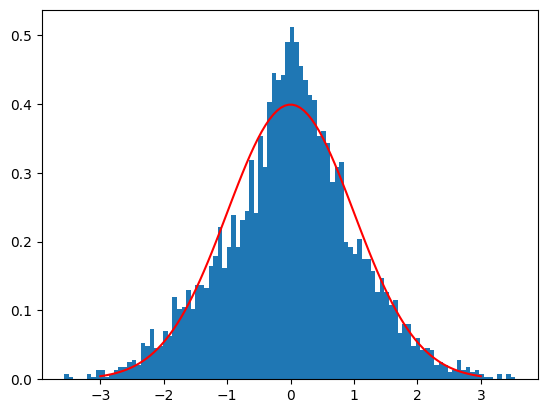

Asset 2 - KS Statistic ($D$): 0.024681
p = 0.0147


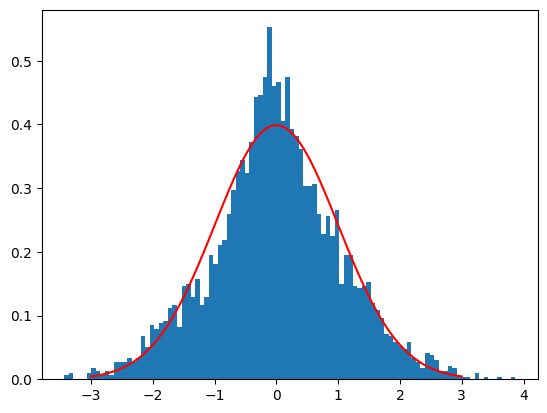

Asset 3 - KS Statistic ($D$): 0.036293
p < 0.001


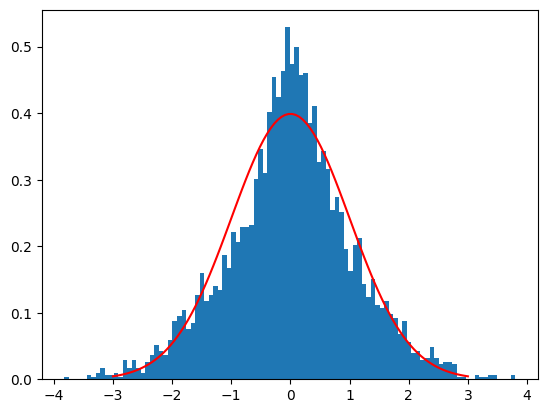

Asset 4 - KS Statistic ($D$): 0.025168
p = 0.0121


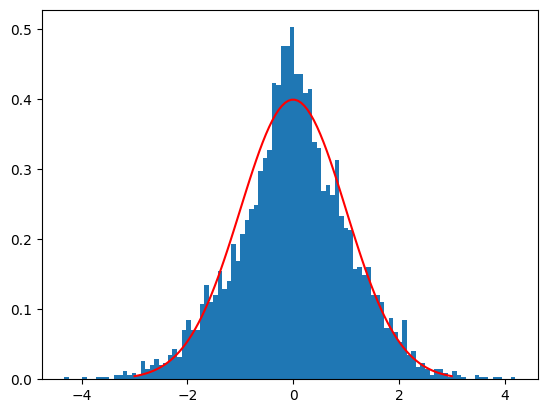

Asset 5 - KS Statistic ($D$): 0.018767
p = 0.1166


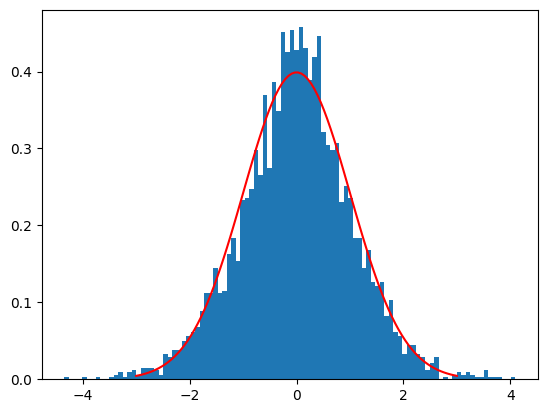

Asset 6 - KS Statistic ($D$): 0.094688
p < 0.001


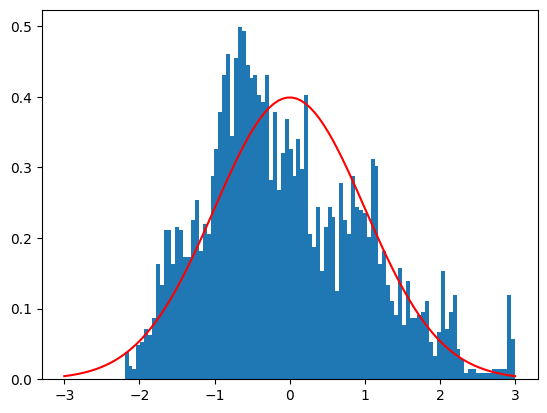

Asset 7 - KS Statistic ($D$): 0.129069
p < 0.001


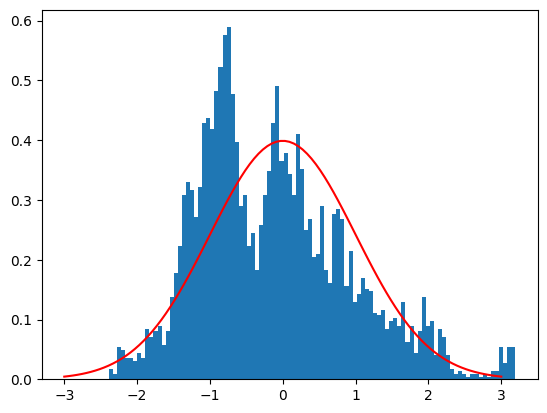

Asset 8 - KS Statistic ($D$): 0.088615
p < 0.001


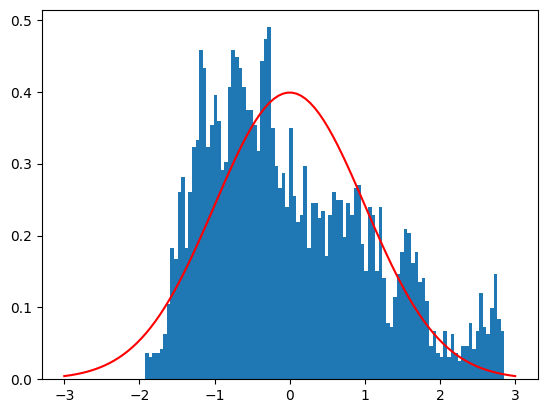

Asset 9 - KS Statistic ($D$): 0.119419
p < 0.001


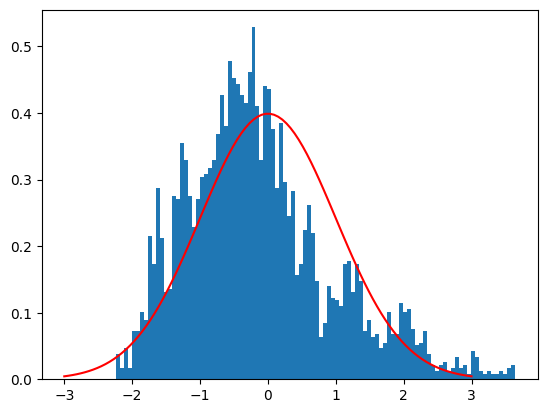

Asset 10 - KS Statistic ($D$): 0.038753
p < 0.001


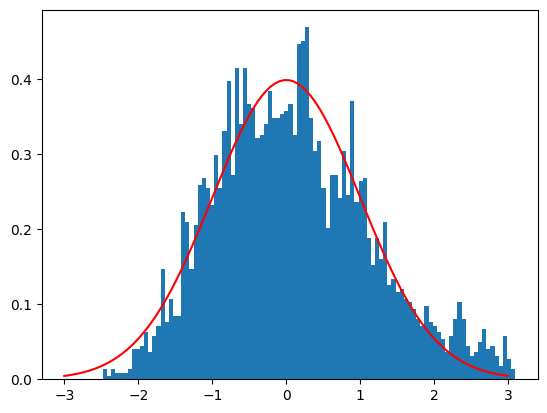

Asset 11 - KS Statistic ($D$): 0.054155
p < 0.001


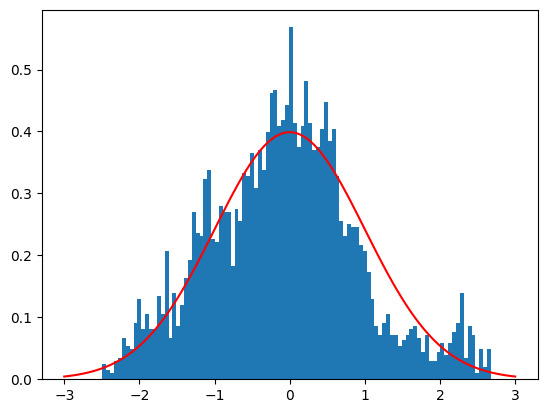

In [5]:
import matplotlib.pyplot as plt
from scipy.stats import kstest

for i in range(12):
    data = train_12d[:, i]
    # data = winsorize(data, limits=[0.01, 0.01])
    ks_stat, p_val = kstest(data, "norm")

    # 학술적 표기법: p-value가 매우 작을 경우 < 0.001로 표기
    p_text = f"p < 0.001" if p_val < 0.001 else f"p = {p_val:.4f}"
    ks_results_text = f"KS Statistic ($D$): {ks_stat:.6f}\n{p_text}"
    print(f"Asset {i} - {ks_results_text}")
    plt.hist(data, bins=100, density=True)
    plt.plot(
        np.linspace(-3, 3, 100), norm.pdf(np.linspace(-3, 3, 100), 0, 1), color="red"
    )
    plt.show()
    gc.collect()

In [6]:
# import matplotlib.pyplot as plt
# from scipy.stats import kstest

# for i in range(12):
#     data =  train_12d[:,i]
#     # data = winsorize(data, limits=[0.01, 0.01])
#     ks_stat, p_val = kstest(data, 'norm')

#     # 학술적 표기법: p-value가 매우 작을 경우 < 0.001로 표기
#     p_text = f"p < 0.001" if p_val < 0.001 else f"p = {p_val:.4f}"
#     ks_results_text = f"KS Statistic ($D$): {ks_stat:.6f}\n{p_text}"
#     print(f"Asset {i} - {ks_results_text}")
#     plt.hist(data, bins=100, density=True)
#     plt.plot(np.linspace(-3, 3, 100), norm.pdf(np.linspace(-3, 3, 100), 0, 1), color='red')
#     plt.show()
#     gc.collect()

In [7]:
configs = {
    "enc_in": training_data.shape[2],
    "dims": [128, 128, 128],
    # "dims": [64, 96, 64],
    "large_size": [15, 7, 5],
    # "large_size": [51, 41, 39],
    "small_size": [3, 3, 3],
    "time_emb_dim": 256,
    "use_time_emb": True,
    "use_cross_attention": True,
    "max_seq_len": training_data.shape[1],
    "use_sequence_pos_encoding": False,
}


ts_model = ModernTCN(configs)

# ---------- Time Series DDPM 학습 ----------
# 위에서 정의한 train_dl, ts_model(ModernTCN), test_data 사용
seq_len = training_data.shape[1]  # 128
num_channels = training_data.shape[2]  # 6


os.makedirs(file_manager.get_weight_path(), exist_ok=True)
# 학습 설정
num_epochs = 75
log_every = 1
train_iter = 0

# 스케줄 및 diffusion 생성
# betas = generate_linear_schedule(100, 1e-5, 0.1)
# betas = generate_linear_schedule(500, 1e-5, 0.02)
# betas = generate_linear_schedule(1500, 1e-4, 0.005) # linear best
# betas = generate_linear_schedule(75, 1e-5, 0.1) # linear best
betas = generate_cosine_schedule(75, 1.5, 1e-5, 0.5)  # cosine best
diffusion = TimeSeriesGaussianDiffusion(
    ts_model,
    seq_len=seq_len,
    num_channels=num_channels,
    betas=betas,
    loss_type="11",
    ema_decay=0.9999,
    ema_start=2000,
    ema_update_rate=1,
    sampling_type="joint_student_t",
    prediction_type="epsilon",
).to(device)

optimizer = torch.optim.Adam(diffusion.parameters(), lr=2e-4, weight_decay=1e-5)

# 1. 경로 설정 및 초기화
result_path = f"{file_manager.get_result_path(diffusion.sampling_type)}"
os.makedirs(result_path, exist_ok=True)

count_parameters(ts_model)
print(diffusion.sampling_type)

c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\modules\diffusion.py:126: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  to_torch = lambda x: torch.tensor(x, dtype=torch.float32)


✅ 전체 파라미터 수: 739,084
✅ 학습 가능한 파라미터 수: 739,084
joint_student_t


# Model Training

In [ ]:
# --- [2. 체크포인트 로드 및 Resume 로직] ---
weight_dir = file_manager.get_weight_path()
start_epoch = 0
ckpts = glob.glob(os.path.join(weight_dir, "quantDiffusion_[0-9]*.pt"))

if ckpts:

    def _epoch_from_path(p):
        stem = os.path.basename(p).replace("quantDiffusion_", "").replace(".pt", "")
        try:
            return int(stem)
        except ValueError:
            return -1

    epochs_found = [e for e in (_epoch_from_path(p) for p in ckpts) if e >= 0]
    if epochs_found:
        resume_epoch = max(epochs_found)
        start_epoch = resume_epoch + 1  # 다음 에폭부터 시작
        latest_ckpt = os.path.join(weight_dir, f"quantDiffusion_{resume_epoch}.pt")
        # map_location을 사용하여 GPU 메모리 중복 점유 방지
        diffusion.load_state_dict(torch.load(latest_ckpt, map_location=device))
        print(f"✅ Resumed from {latest_ckpt}, starting from epoch {start_epoch}")

diffusion.to(device)
clean_memory(device)  # 학습 시작 전 초기화

# --- [4. 메인 학습 루프] ---
pbar = tqdm(range(start_epoch, num_epochs + 1))
for epoch in pbar:
    diffusion.train()
    epoch_loss = 0.0
    n_batches = 0
    epoch_acf_loss = 0.0

    for batch in train_dl:
        # 데이터 이동
        x = batch[0].to(device)

        # Loss 계산 및 역전파
        loss = diffusion(x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # EMA 업데이트
        diffusion.update_ema()

        # 통계 누적
        epoch_loss += loss.item()

        n_batches += 1
        train_iter += 1

        # 배치 데이터 명시적 삭제로 메모리 확보
        del x, loss

    # 에폭 종료 후 평균 train 로스
    avg_loss = epoch_loss / n_batches

    pbar.set_description(f"Epoch {epoch}")
    pbar.set_postfix(train_loss=f"{avg_loss:.4f}")

    # 로그 기록 및 주기적 체크포인트 저장
    if (epoch % log_every == 0) and (epoch != 0):
        torch.save(diffusion.state_dict(), f"{weight_dir}/quantDiffusion_{epoch}.pt")

    if (epoch % 10 == 0) and (epoch != 0):
        print_memory_stats(device)
        clean_memory(device)

Epoch 2:   4%|▍         | 3/76 [00:11<04:22,  3.60s/it, train_loss=0.2195]

# Model Validation

In [ ]:
min_dist = float("inf")
best_epoch = -1

# ⭐ 최적화 1: 훈련 데이터의 역변환은 루프 밖에서 단 1번만 수행!
print("⏳ 훈련 데이터(Real) 역변환 사전 처리 중...")
real_data = torch.from_numpy(rolling_window(train_raw, seq_len)).float().transpose(1, 2)
print("✅ Real Data 준비 완료.")

pbar = tqdm(range(25, num_epochs, log_every))

for epoch in pbar:
    clean_memory(device)

    ckpt_path = f"{file_manager.get_weight_path()}/quantDiffusion_{epoch}.pt"
    if not os.path.exists(ckpt_path):
        continue

    diffusion.load_state_dict(torch.load(ckpt_path, map_location=device))
    diffusion.to(device)
    diffusion.eval()

    with torch.no_grad():
        # 1. 샘플 생성
        fake = diffusion.sample(batch_size=100, device=device, use_ema=True)

        # Z_generated는 Diffusion 모델이 방금 뱉어낸 가짜 잔차 텐서입니다.
        # 현실 시장에서 3.0 표준편차를 넘어가는 일은 극히 드뭅니다.

        # 2. Fake 데이터 MODWT 및 스케일 역변환
        # reconstructed_fake = inverse_modwt(fake, processors)
        fake_data = inverse_garch_12d_to_6d(fake, scalers)

        print("-" * 30)
        print(
            f"Fake Latent - Mean: {fake.mean().item():.4f}, Std: {fake.std().item():.4f}"
        )
        print(
            f"Real Latent - Mean: {training_data.mean().item():.4f}, Std: {training_data.std().item():.4f}"
        )
        print("-" * 30)

        # 3. EMD 지표 계산 (이미 계산해둔 real_data 활용)
        emd = compute_avg_emd(real_data, fake_data, 100)

        # 4. 최적 에폭 업데이트
        if emd < min_dist:
            min_dist = emd
            best_epoch = epoch
            pbar.set_description(f"⭐ Best EMD: {min_dist:.5f} (Epoch {best_epoch})")
        else:
            pbar.set_postfix(current_emd=f"{emd:.5f}")

        # 5. 메모리 해제
        del fake, fake_data

# --- [마무리: Best 모델 보존 및 가중치 정리] ---
if best_epoch != -1:
    print(f"\n🏆 최종 선정된 Best Epoch: {best_epoch} (EMD: {min_dist:.5f})")

    # ⭐ 최적화 2: 모델을 다시 Load/Save 할 필요 없이, 파일 복사(Copy)로 디스크 I/O 최소화
    best_ckpt_path = f"{file_manager.get_weight_path()}/quantDiffusion_{best_epoch}.pt"
    final_best_path = f"{result_path}/quantDiffusion_best({best_epoch}).pt"

    os.makedirs(result_path, exist_ok=True)
    diffusion.load_state_dict(torch.load(best_ckpt_path, map_location=device))
    torch.save(
        diffusion.state_dict(), f"{result_path}/quantDiffusion_best({best_epoch}).pt"
    )
    print(f"💾 Best 모델 저장 완료: {final_best_path}")

    # 불필요한 중간 가중치 파일 삭제 (단, Best 원본은 보호)
    weight_path = file_manager.get_weight_path()
    search_pattern = os.path.join(weight_path, "quantDiffusion_*.pt")
    files_to_delete = glob.glob(search_pattern)

    if files_to_delete:
        print(f"🧹 불필요한 가중치 정리 중...")
        for file_path in files_to_delete:
            # 방금 복사한 원본 Best 가중치이거나, 최종 결과물이면 삭제 건너뛰기
            if file_path == best_ckpt_path or file_path == final_best_path:
                continue
            try:
                os.remove(file_path)
            except Exception:
                pass
        print("✅ 가중치 파일 정리가 완료되었습니다.")
else:
    print("❌ 유효한 체크포인트를 찾지 못했습니다.")

⏳ 훈련 데이터(Real) 역변환 사전 처리 중...
✅ Real Data 준비 완료.


  0%|          | 0/50 [00:00<?, ?it/s]

------------------------------
Fake Latent - Mean: 0.0000, Std: 0.9980
Real Latent - Mean: -0.0195, Std: 1.0507
------------------------------


⭐ Best EMD: 0.21651 (Epoch 25):   2%|▏         | 1/50 [00:07<06:10,  7.56s/it]

------------------------------
Fake Latent - Mean: 0.0000, Std: 0.9980
Real Latent - Mean: -0.0195, Std: 1.0507
------------------------------


...

------------------------------
Fake Latent - Mean: 0.0000, Std: 0.9980
Real Latent - Mean: -0.0195, Std: 1.0507
------------------------------


⭐ Best EMD: 0.14608 (Epoch 53):  98%|█████████▊| 49/50 [06:13<00:07,  7.40s/it, current_emd=0.15775]

------------------------------
Fake Latent - Mean: -0.0000, Std: 0.9980
Real Latent - Mean: -0.0195, Std: 1.0507
------------------------------


⭐ Best EMD: 0.14608 (Epoch 53): 100%|██████████| 50/50 [06:21<00:00,  7.63s/it, current_emd=0.25147]


🏆 최종 선정된 Best Epoch: 53 (EMD: 0.14608)
💾 Best 모델 저장 완료: c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\result/statistics/synthetic_data/joint_student_t/quantDiffusion_best(53).pt
🧹 불필요한 가중치 정리 중...
✅ 가중치 파일 정리가 완료되었습니다.


# Save synthetic data

In [ ]:
# --- [1. 모델 로드 및 최신 파일 검색] ---
# 가중치가 저장된 경로에서 패턴에 맞는 파일들을 모두 가져옵니다.
search_pattern = f"{result_path}/quantDiffusion_best*.pt"
best_files = glob.glob(search_pattern)

if best_files:
    # os.path.getmtime(파일 수정 시간)을 키로 사용하여 가장 최근 파일을 찾습니다.
    # 생성된 지 가장 얼마 안 된(가장 큰 시간 값) 파일을 선택합니다.
    target_file = max(best_files, key=os.path.getmtime)

    # 가중치 로드 시 map_location을 설정하여 GPU 메모리 중복 점유를 방지합니다.
    diffusion.load_state_dict(torch.load(target_file, map_location=device))

    print(f"✅ 최신 가중치 로드 완료: {os.path.basename(target_file)}")
else:
    print(f"❌ 해당 경로({result_path})에 'quantDiffusion_best*.pt' 파일이 없습니다.")

# 모델을 디바이스로 이동시키고 평가 모드로 전환합니다.
diffusion.to(device)
diffusion.eval()

# 루프 시작 전 GPU/RAM 상태를 출력하여 리소스 가용량을 확인합니다.
print_memory_stats(device, prefix="🚀 Inference Ready:")

real_data = test_data.transpose(1, 2)
train_data = (
    torch.from_numpy(rolling_window(train_raw, seq_len)).float().transpose(1, 2)
)
if hasattr(real_data, "cpu"):
    real_data = real_data.cpu().detach().numpy()
    train_data = train_data.cpu().detach().numpy()
# --- [2. 안전한 이상치 필터링 경계값 계산] ---
# 실제 데이터의 각 피처별 최소/최대값을 구합니다.
min_vals = train_data.min(axis=(0, 2), keepdims=True)
max_vals = train_data.max(axis=(0, 2), keepdims=True)

# 단순 곱셈이 아닌, 실제 데이터의 '진폭(Range)'을 기준으로 50%의 여유 공간을 둡니다.
range_margin = (max_vals - min_vals) * 0.1
lower_bound = min_vals - range_margin
upper_bound = max_vals + range_margin

train_min = train_windowed.amin(dim=(0, 1))  # 결과 shape: [12]
train_max = train_windowed.amax(dim=(0, 1))  # 결과 shape: [12]


# def smart_clamp(samples, train_min, train_max):
#     # samples: [B, T, 12], train_min: [1, 1, 12]
#     # 텐서에서 값만 추출하기 위해 flatten() 처리
#     t_min = train_min.flatten()
#     t_max = train_max.flatten()

#     for d in range(12):
#         # 학습 데이터의 진폭을 기준으로 5% 여유 부여
#         margin = (t_max[d] - t_min[d]) * 0.1
#         low = t_min[d] - margin
#         high = t_max[d] + margin

#         # 해당 차원(d)만 클램핑
#         samples[:, :, d] = torch.clamp(samples[:, :, d], min=low, max=high)
#     return samples

✅ 최신 가중치 로드 완료: quantDiffusion_best(53).pt
🚀 Inference Ready: [RAM: 50.1%] [VRAM Alloc: 14.1MB / Resrv: 300.0MB]


## Cross-Attention 위치(선후 관계) 점검
Positional Encoding이 있으면 **입력을 시간축으로 뒤집었을 때** 출력이 단순 뒤집기와 달라야 합니다.  
`flip_diff`가 충분히 크면 위치 정보가 반영되고 있는 것이고, 너무 작으면 '전체 평균'에만 의존할 수 있습니다.

In [ ]:
from utils.metric import check_attention_position_sensitivity

# 배치 하나로 위치 민감도 진단 (모델 생성 직후 또는 학습 후 실행)
batch = next(iter(train_dl))
x_check = batch[0].to(device)
diag = check_attention_position_sensitivity(ts_model, x_check, device=device)
print("flip_diff (클수록 시계열 선후 관계 반영):", diag["flip_diff"])
print("position_sensitive:", diag["position_sensitive"])
print("(use_sequence_pos_encoding=True이고 flip_diff가 1e-5보다 크면 PE가 동작 중)")

flip_diff (클수록 시계열 선후 관계 반영): 0.12162663787603378
position_sensitive: True
(use_sequence_pos_encoding=True이고 flip_diff가 1e-5보다 크면 PE가 동작 중)


In [ ]:
# --- [3. 데이터 생성 루프] ---
for run_idx in range(1):
    batch_size_small = 100
    num_iterations = 25  # 100개씩 20번 = 2000개
    all_samples_list = []

    with torch.no_grad():
        for i in range(num_iterations):
            sample_batch = diffusion.sample(
                batch_size=batch_size_small, device=device, use_ema=True
            )
            all_samples_list.append(sample_batch)
            print_memory_stats(
                device,
                f"  📦 {(i+1) * batch_size_small}/{num_iterations*batch_size_small}",
            )

    # 병합 전 메모리 정리 권장
    samples = torch.cat(all_samples_list, dim=0)

    # 적용 예시
    # samples = smart_clamp(samples, train_min, train_max)
    print(samples.shape)
    # 텐서 병합 후 리스트 비우기 (메모리 절약)
    del all_samples_list
    clean_memory(device)  # 병합 후 남은 파편 메모리 정리

    # samples = torch.clamp(samples, min=-1.0, max=1.0)
    fake_data = inverse_garch_12d_to_6d(samples, scalers)
    mask = np.all((fake_data >= lower_bound) & (fake_data <= upper_bound), axis=(1, 2))
    filtered_data = fake_data[mask]
    emd = compute_avg_emd(real_data, filtered_data, 100)
    print(f"📊 min_distance (EMD): {emd:.5f}")
    print(f"🔍 필터링 후 생존 개수: {len(filtered_data)}")

    # 2. 최종 2,000개 무작위 선택 (Safety Logic 포함)
    target_n = 2000
    if len(filtered_data) >= target_n:
        # 무작위 인덱스 추출 후 할당
        idx = np.random.choice(len(filtered_data), target_n, replace=False)
        final_fake_data = filtered_data[idx]
    else:
        # 만약 필터링 결과가 2000개보다 적으면, 있는 거라도 다 씀
        print(
            f"⚠️ 경고: 필터링 결과가 {target_n}개보다 적습니다. 전체({len(filtered_data)}개)를 저장합니다."
        )
        final_fake_data = filtered_data

    # 3. 저장
    np.save(os.path.join(result_path, f"{run_idx}.npy"), final_fake_data)
    print(f"✅ Run {run_idx+1} 완료. Final Shape: {final_fake_data.shape}")
    print_memory_stats(device, "🧹 After Clean:")

# del samples, fake_data, filtered_data
clean_memory(device)

  📦 100/2500 [RAM: 50.1%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 200/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 300/2500 [RAM: 50.3%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 400/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 500/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 600/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 700/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 800/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 900/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1000/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1100/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1200/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1300/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1400/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1500/2500 [RAM: 50.2%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1600/2500 [RAM: 50.2%] [VRAM A

# Evaluation

In [ ]:
result_path = f"{file_manager.get_result_path(diffusion.sampling_type)}"
total_result_df = pd.DataFrame()
for seed in range(1):
    fake_data = np.load(f"{result_path}/{seed}.npy")

    print(fake_data.shape)
    fake_list = [fake_data[:, i, :] for i in range(fake_data.shape[1])]
    real_list = [real_data[:, i, :] for i in range(real_data.shape[1])]

    """ Visualize the distribution of the real and fake data """

    # Plot the distribution of the real and fake data
    windows = [1, 5, 20, 100]

    result_df = pd.DataFrame()
    CCF_df = calculate_ccf(real_data, fake_data, 0)
    result_df = pd.concat([result_df, CCF_df], axis=0)
    total_CCF_df = pd.DataFrame(columns=["Average"])
    for i in range(1, 11):
        total_CCF_df = pd.concat(
            [total_CCF_df, calculate_ccf(real_data, fake_data, i)], axis=1
        )

    result_df = pd.concat(
        [result_df, pd.DataFrame(total_CCF_df.mean(axis=1), columns=["Average"])],
        axis=0,
    )

    similarity_df = calculate_distribution_scores(real_data, fake_data, windows)
    result_df = pd.concat([result_df, similarity_df], axis=0)
    skew_kurt_df = calculate_skew_kurtosis(real_data, fake_data, windows)
    result_df = pd.concat([result_df, skew_kurt_df], axis=0)
    _, acf_df = calculate_acf_score(real_data, fake_data, 40)
    result_df = pd.concat([result_df, acf_df], axis=0)
    _, leverage_df = calculate_leverage_effect(real_data, fake_data, 40)
    result_df = pd.concat([result_df, leverage_df], axis=0)

    total_result_df = pd.concat([total_result_df, result_df], axis=1)

statistics_df = pd.DataFrame(index=total_result_df.index, columns=["MEAN", "STD"])
statistics_df.loc[statistics_df.index, "MEAN"] = total_result_df.mean(axis=1).values
statistics_df.loc[statistics_df.index, "STD"] = total_result_df.std(axis=1).values
statistics_df.to_csv(
    file_manager.get_result_file(f"{diffusion.sampling_type}_gen_quality")
)
print(statistics_df)

(2000, 6, 256)
                    MEAN  STD
CCF(τ = 0)_MAE    0.0403  NaN
CCF(τ = 0)_FROB   0.3659  NaN
CCF(τ = 0)_MSE    0.0037  NaN
CCF(τ > 0)_MAE   0.03308  NaN
CCF(τ > 0)_FROB  0.64651  NaN
CCF(τ > 0)_MSE   0.00199  NaN
EMD(1)            0.0013  NaN
EMD(5)            0.0038  NaN
EMD(20)           0.0117  NaN
EMD(100)          0.0267  NaN
KS(1)             0.0371  NaN
KS(5)             0.0478  NaN
KS(20)            0.0678  NaN
KS(100)           0.1041  NaN
Skew(1)           0.1634  NaN
Skew(5)           0.1918  NaN
Skew(20)           0.195  NaN
Skew(100)         0.0668  NaN
Kurt(1)           1.3918  NaN
Kurt(5)           0.4157  NaN
Kurt(20)          0.3564  NaN
Kurt(100)         0.2468  NaN
ACF(x)             0.001  NaN
ACF(|x|)          0.0013  NaN
ACF(x^2)           0.001  NaN
Leverage Effect    0.001  NaN


In [ ]:
for seed in range(1):
    fake_data = np.load(f"{result_path}/{seed}.npy")
    eval_size = real_data.shape[0]

    fake_data_torch = torch.from_numpy(fake_data).float().transpose(1, 2)
    real_data_torch = torch.from_numpy(real_data).float().transpose(1, 2)

    train_init_price = train_init_raw.reshape(-1, 1, 6)
    train_init_price[:] = 100

    # 1. 원본 데이터를 보존하기 위해 clone()을 사용하고, 100으로 초기화합니다.
    # (test_init_price = train_init_price 라고 하면 원본 값도 100으로 바뀝니다)
    test_init_price = test_init_raw.reshape(-1, 1, 6)
    test_init_price[:] = 100

    # 2. 평가할 실제 데이터의 양을 정확히 계산합니다.
    # fake_data_torch가 eval_size보다 작을 경우를 대비합니다.
    actual_eval_data = fake_data_torch[:eval_size]
    n_samples = actual_eval_data.shape[0]

    # 3. 데이터 개수(n_samples)에 맞춰서 초기 가격도 똑같이 잘라줍니다.
    fake_prices = log_return_to_price(
        actual_eval_data,
        torch.tensor(
            train_init_price[:n_samples],
            dtype=torch.float32,
            device=actual_eval_data.device,
        ),
    )
    real_prices = log_return_to_price(
        real_data_torch[:n_samples],
        torch.tensor(
            test_init_price[:n_samples],
            dtype=torch.float32,
            device=actual_eval_data.device,
        ),
    )

    config_dir = f"{LOCAL_BASE_DIRECTORY}/utils/eval_portfolio/config.yaml"
    with open(config_dir) as file:
        eval_config = ml_collections.ConfigDict(yaml.safe_load(file))

    all_positive = (fake_prices > 0).all()
    if not all_positive:
        raise ValueError("Sanity Check Failed: Some fake prices are not positive.")

    res_dict = {
        "var_abs_mean": 0.0,
        "var_rel_mean": 0.0,
        "es_abs_mean": 0.0,
        "es_rel_mean": 0.0,
    }

    # 1. 설정 및 변수 준비
    alphas = eval_config.alphas  # [0.05, 0.025, 0.01]
    strat_names = ["equal_weight", "mean_reversion", "trend_following", "vol_trading"]
    # 표시용 약어 매핑
    strat_map = {
        "equal_weight": "EW",
        "mean_reversion": "MR",
        "trend_following": "TF",
        "vol_trading": "VT",
    }

    # 결과를 저장할 중첩 딕셔너리 {Metric(alpha): {Strategy: Value}}
    final_results = {}

    with torch.no_grad():
        for alpha in alphas:
            # Config의 alpha 설정 동기화
            eval_config.Evaluation.TestMetrics.var.alpha = alpha
            eval_config.Evaluation.TestMetrics.es.alpha = alpha

            # 각 Metric별로 전략들의 수치를 담을 임시 딕셔너리
            var_row = {}
            es_row = {}

            for strat_name in strat_names:
                # 전략별 평가 수행
                subres_dict, _, _ = full_evaluation(
                    fake_prices, real_prices, eval_config, strat_name=strat_name
                )

                # 약어 이름으로 개별 전략 결과 저장
                short_name = strat_map[strat_name]
                var_row[short_name] = round(subres_dict.get("var_rel_mean", 0.0), 4)
                es_row[short_name] = round(subres_dict.get("es_rel_mean", 0.0), 4)

            # 4개 전략의 평균(Average) 계산 및 추가
            var_row["Average"] = round(np.mean(list(var_row.values())), 4)
            es_row["Average"] = round(np.mean(list(es_row.values())), 4)

            # 최종 결과 사전에 인덱스 명칭으로 저장
            final_results[f"RE_VaR({alpha})"] = var_row
            final_results[f"RE_ES({alpha})"] = es_row

    # 2. DataFrame 포맷팅
    # Metric 순서 정의 (VaR 그룹 후 ES 그룹)
    metrics = ["RE_VaR", "RE_ES"]
    ordered_keys = [f"{m}({a})" for m in metrics for a in alphas]

    # 딕셔너리로부터 DataFrame 생성 및 컬럼 순서 정렬
    df_final = pd.DataFrame.from_dict(final_results, orient="index")
    cols_order = [strat_map[s] for s in strat_names] + ["Average"]
    df_final = df_final.reindex(index=ordered_keys, columns=cols_order)
    df_final.index.name = "Metric"
    df_final.T.to_csv(
        file_manager.get_result_file(f"{diffusion.sampling_type}_{seed}_portfolio")
    )

print(df_final.T)

49
65
61
58
77
89
49
65
61
58
77
89
49
65
61
58
77
89
Metric   RE_VaR(0.05)  RE_VaR(0.025)  RE_VaR(0.01)  RE_ES(0.05)  RE_ES(0.025)  \
EW             0.0371         0.0480        0.0775       0.0543        0.0704   
MR             0.0402         0.0481        0.0480       0.0400        0.0452   
TF             0.0121         0.0172        0.0333       0.0220        0.0330   
VT             0.0086         0.0110        0.0199       0.0130        0.0194   
Average        0.0245         0.0311        0.0447       0.0323        0.0420   

Metric   RE_ES(0.01)  
EW            0.0887  
MR            0.0606  
TF            0.0501  
VT            0.0277  
Average       0.0568  


KeyboardInterrupt: 

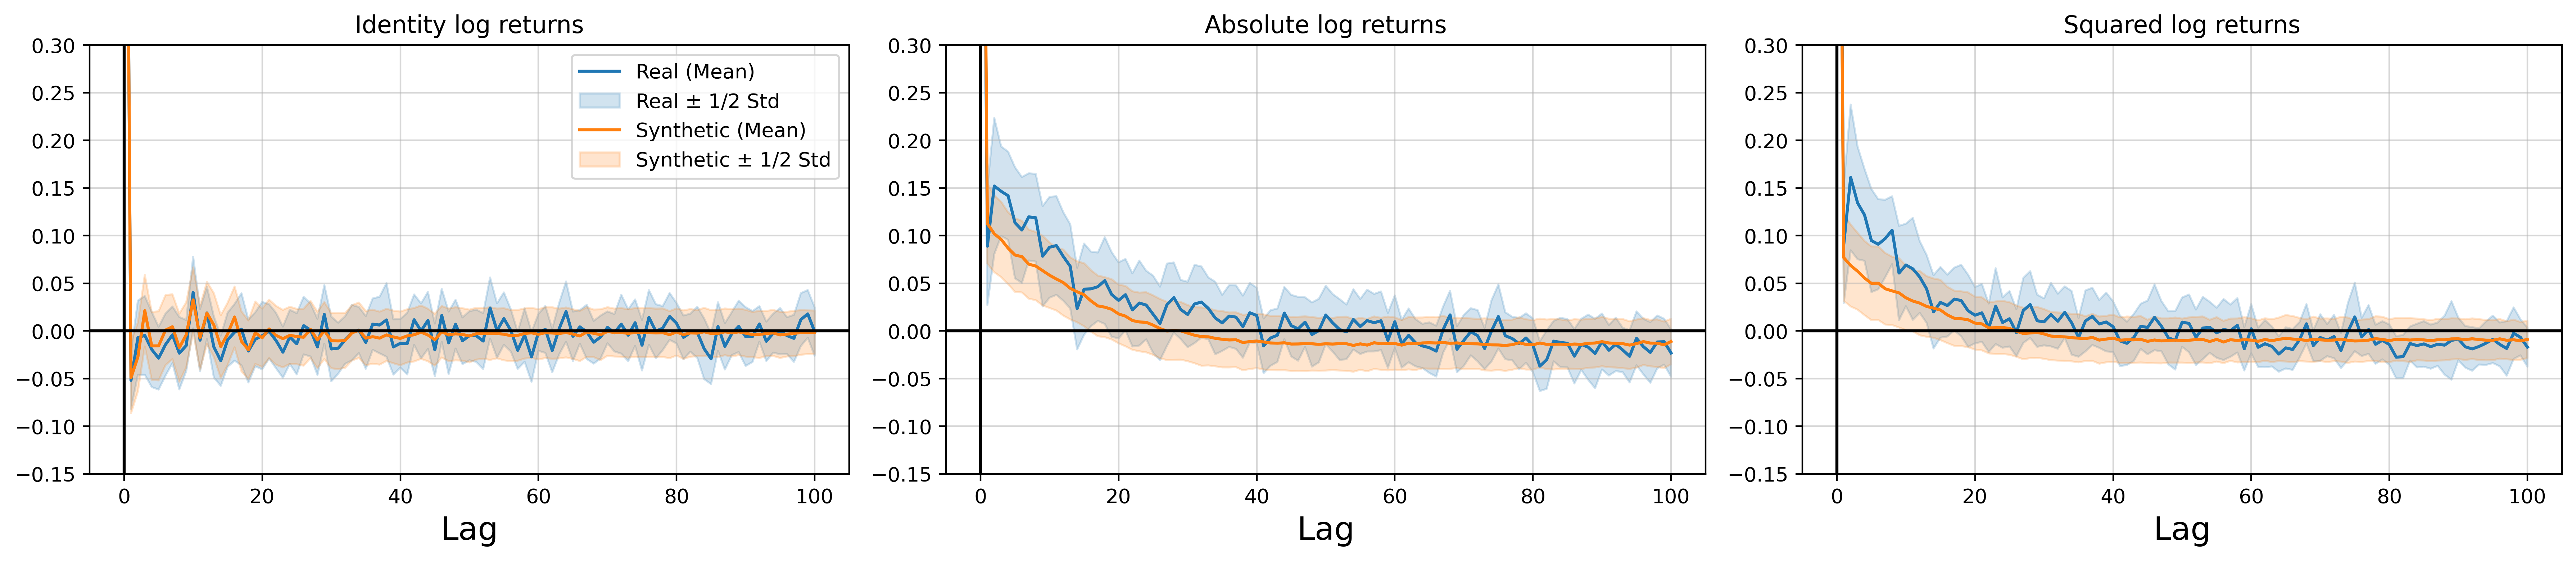

In [ ]:
real_list = [train_data[:, i, :] for i in range(train_data.shape[1])]
# 상관행렬 계산을 위해 데이터 전치 (shape: (num_samples, num_time_steps, num_features))
real_mean_corr = correlation_mean(np.transpose(train_data, (0, 2, 1)))
fake_mean_corr = correlation_mean(np.transpose(fake_data, (0, 2, 1)))

feature_names = ["DJI", "NASDAQ", "JPM", "HSI", "GOLD", "WTI_OIL"]

plot_correlation_heatmap(
    real_mean_corr, "Real Data", feature_names, diffusion.sampling_type
)
plot_correlation_heatmap(
    fake_mean_corr, "Fake Data", feature_names, diffusion.sampling_type
)
plot_cumulative_return_dist(
    real_list, fake_list, windows, sampling_type=diffusion.sampling_type
)
plot_acf_comparison(real_list, fake_list, 6, 100, sampling_type=diffusion.sampling_type)

In [ ]:
# STATS_DIR = os.path.join(file_manager.base_directory, "result/statistics")

# NDIGITS = 4


# def fmt_pm(m, s, ndigits=NDIGITS):
#     """mean과 std를 한 문자열로 (± U+00B1)."""
#     if not np.isfinite(m) or not np.isfinite(s):
#         return ""
#     return f"{m:.{ndigits}f} \u00b1 {s:.{ndigits}f}"


# def agg_mean_std_to_pm(agg_ms: pd.DataFrame, ndigits=NDIGITS) -> pd.DataFrame:
#     """컬럼이 metric_mean, metric_std 인 DataFrame -> metric 한 컬럼씩 ± 문자열."""
#     means = [c for c in agg_ms.columns if str(c).endswith("_mean")]
#     bases = [str(c)[:-5] for c in means]
#     out = pd.DataFrame(index=agg_ms.index)
#     for b in bases:
#         out[b] = [
#             fmt_pm(mm, ss, ndigits)
#             for mm, ss in zip(agg_ms[f"{b}_mean"], agg_ms[f"{b}_std"])
#         ]
#     return out


# # ---------- Portfolio ----------
# def load_portfolio_csvs(sampling_type=None):
#     paths = sorted(glob.glob(os.path.join(STATS_DIR, "*_portfolio.csv")))
#     if sampling_type is not None:
#         prefix = f"{sampling_type}_"
#         paths = [p for p in paths if os.path.basename(p).startswith(prefix)]
#     if not paths:
#         raise FileNotFoundError(
#             f"portfolio csv 없음: {STATS_DIR} (sampling_type={sampling_type!r})"
#         )
#     parts = [pd.read_csv(p, index_col=0) for p in paths]
#     stacked = pd.concat(parts, axis=0)
#     return stacked, paths


# def portfolio_summary_pm(sampling_type=None, ndigits=NDIGITS):
#     stacked, paths = load_portfolio_csvs(sampling_type=sampling_type)
#     agg = stacked.groupby(level=0).agg(["mean", "std"])
#     agg.columns = [f"{c}_{s}" for c, s in agg.columns]
#     return agg_mean_std_to_pm(agg, ndigits), agg, stacked, paths


# # ---------- Gen quality ----------
# def load_gen_quality_csvs(sampling_type=None):
#     paths = sorted(glob.glob(os.path.join(STATS_DIR, "*_gen_quality.csv")))
#     if sampling_type is not None:
#         prefix = f"{sampling_type}_"
#         paths = [p for p in paths if os.path.basename(p).startswith(prefix)]
#     return paths


# def gen_quality_summary_pm(sampling_type=None, ndigits=NDIGITS):
#     paths = load_gen_quality_csvs(sampling_type=sampling_type)
#     if not paths:
#         raise FileNotFoundError(
#             f"gen_quality csv 없음: {STATS_DIR} (sampling_type={sampling_type!r})"
#         )
#     parts = [pd.read_csv(p, index_col=0) for p in paths]
#     if len(parts) == 1:
#         df = parts[0]
#         col = pd.Series(
#             [fmt_pm(df.loc[i, "MEAN"], df.loc[i, "STD"], ndigits) for i in df.index],
#             index=df.index,
#             name="mean \u00b1 std",
#         )
#         pm = col.to_frame()
#         agg = None
#     else:
#         stacked = pd.concat(parts, axis=0)
#         g = stacked.groupby(level=0)["MEAN"].agg(["mean", "std"])
#         g.columns = ["mean_mean", "mean_std"]
#         pm = pd.DataFrame(
#             {
#                 "mean \u00b1 std (across files)": [
#                     fmt_pm(a, b, ndigits) for a, b in zip(g["mean_mean"], g["mean_std"])
#                 ]
#             },
#             index=g.index,
#         )
#         agg = g
#     return pm, agg, paths


# SAMPLING_TYPE = "joint_student_t"

# portfolio_pm, portfolio_agg, portfolio_stacked, portfolio_paths = portfolio_summary_pm(
#     SAMPLING_TYPE
# )

# gen_pm, gen_agg, gen_paths = gen_quality_summary_pm(SAMPLING_TYPE)
# # Excel: UTF-8 그대로, 열 너비는 기본 (±·한글·τ 보존)
# OUT_XLSX = os.path.join(
#     STATS_DIR,
#     f"{SAMPLING_TYPE}_statistics_summary_pm.xlsx",
# )
# with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as writer:
#     portfolio_pm.to_excel(writer, sheet_name="portfolio", index=True)
#     gen_pm.to_excel(writer, sheet_name="gen_quality", index=True)
# print("saved:", OUT_XLSX)